# Análise rápida dos prazos originais dos contratos de obras

Este notebook apresenta uma linha por contrato com:

- `id_contrato`;
- `classificacao_contrato`;
- `data_os`;
- `data_termino_original`;
- `status_final_controle`;
- diferença em dias entre `data_termino_original` e `data_os`.

O notebook usa o snapshot mais recente de cada contrato apenas para evitar repetição. Os campos cadastrais analisados são constantes por contrato.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")


## 1. Carregamento do dataset

In [2]:
def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "processed").exists():
            return candidate
    return current.parent if current.name == "notebooks" else current


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports" / "quick_analysis"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

candidates = [
    #PROCESSED_DIR / "dataset_exploratorio_obras.parquet",
    PROCESSED_DIR / "dataset_modelagem_obras_snapshots.csv",
]

source_path = next((path for path in candidates if path.exists()), None)
if source_path is None:
    raise FileNotFoundError(
        "Dataset de obras não encontrado. Execute primeiro "
        "01_dataset_exploratorio_apenas_obras.ipynb."
    )

if source_path.suffix == ".parquet":
    df = pd.read_parquet(source_path)
else:
    df = pd.read_csv(source_path, low_memory=False)

print("Arquivo:", source_path)
print("Snapshots:", len(df))
print("Contratos distintos:", df["id_contrato"].nunique())


Arquivo: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\data\processed\dataset_modelagem_obras_snapshots.csv
Snapshots: 1435
Contratos distintos: 78


## 2. Padronização dos campos

In [3]:
# Aceita tanto os nomes padronizados do dataset quanto nomes da fonte original.
def first_existing(dataframe: pd.DataFrame, names: list[str]) -> str | None:
    return next((name for name in names if name in dataframe.columns), None)


classification_column = first_existing(
    df,
    ["classificacao_contrato", "tipo_obra", "Classificacao_contrato"],
)
data_os_column = first_existing(df, ["data_os", "Data_OS"])
original_end_column = first_existing(
    df,
    ["data_termino_original", "Data_termino_original"],
)
status_column = first_existing(
    df,
    ["status_final_controle", "status_contrato", "Status_Contrato"],
)

required = {
    "classificação": classification_column,
    "data OS": data_os_column,
    "status": status_column,
}
missing = [label for label, column in required.items() if column is None]
if missing:
    raise ValueError(f"Campos obrigatórios não encontrados: {missing}")

# Conversão das datas.
df[data_os_column] = pd.to_datetime(df[data_os_column], errors="coerce")

# Se o término original não existir, calcula Data_OS + prazo_total_informado.
if original_end_column is None:
    if "prazo_total_informado" not in df.columns:
        raise ValueError(
            "Não foi encontrada data_termino_original nem prazo_total_informado."
        )

    df["prazo_total_informado"] = pd.to_numeric(
        df["prazo_total_informado"],
        errors="coerce",
    )
    prazo_valido = (
        df[data_os_column].notna()
        & df["prazo_total_informado"].gt(1)
        & df["prazo_total_informado"].lt(5000)
    )
    df["data_termino_original"] = (
        df[data_os_column]
        + pd.to_timedelta(
            df["prazo_total_informado"].where(prazo_valido),
            unit="D",
        )
    )
    original_end_column = "data_termino_original"
else:
    df[original_end_column] = pd.to_datetime(
        df[original_end_column],
        errors="coerce",
    )


## 3. Uma linha por contrato

In [9]:
# Seleciona o snapshot mais recente somente para evitar contratos repetidos.
latest = (
    df.assign(data_corte=pd.to_datetime(df["data_corte"], errors="coerce"))
    .sort_values(["id_contrato", "data_corte"])
    .groupby("id_contrato", as_index=False)
    .tail(1)
    .copy()
)

analysis = pd.DataFrame({
    "id_contrato": latest["id_contrato"],
    "classificacao_contrato": latest[classification_column],
    "data_os": latest[data_os_column],
    "data_termino_original": latest[original_end_column],
    "status_final_controle": latest[status_column],
})

analysis["diferenca_termino_original_data_os_dias"] = (
    analysis["data_termino_original"] - analysis["data_os"]
).dt.days

analysis = analysis.sort_values("id_contrato").reset_index(drop=True)
analysis.head(80)


,id_contrato,classificacao_contrato,data_os,data_termino_original,status_final_controle,diferenca_termino_original_data_os_dias
0,11,Reforma Parcial,2019-07-24,2019-12-21,CONCLUÍDO,150
1,12,Reforma Parcial,2018-03-22,2018-06-20,CONCLUÍDO,90
2,18,Reforma Parcial,2019-09-11,2020-01-09,CONCLUÍDO,120
3,28,Construção,2018-06-13,2021-05-28,RESCINDIDO,1080
4,29,Reforma Parcial e Ampliação,2019-01-29,2019-09-26,CONCLUÍDO,240
5,30,Reforma Parcial,2020-01-07,2020-04-06,CONCLUÍDO,90
6,31,Reforma Parcial,2019-07-11,2019-11-08,CONCLUÍDO,120
7,32,Reforma Parcial,2020-01-27,2020-04-26,CONCLUÍDO,90
8,33,Construção,2018-10-08,2020-07-29,CONCLUÍDO,660
9,45,Reforma Global e Ampliação,2019-04-25,2022-08-07,RESCINDIDO,1200


## 4. Resumo da qualidade

In [5]:
quality = pd.DataFrame({
    "indicador": [
        "Contratos exibidos",
        "Data OS ausente",
        "Data de término original ausente",
        "Classificação ausente",
        "Status ausente",
        "Diferença negativa",
    ],
    "quantidade": [
        len(analysis),
        analysis["data_os"].isna().sum(),
        analysis["data_termino_original"].isna().sum(),
        analysis["classificacao_contrato"].isna().sum(),
        analysis["status_final_controle"].isna().sum(),
        analysis["diferenca_termino_original_data_os_dias"].lt(0).sum(),
    ],
})
quality


,indicador,quantidade
0,Contratos exibidos,78
1,Data OS ausente,0
2,Data de término original ausente,0
3,Classificação ausente,0
4,Status ausente,0
5,Diferença negativa,0


## 5. Distribuição da duração original

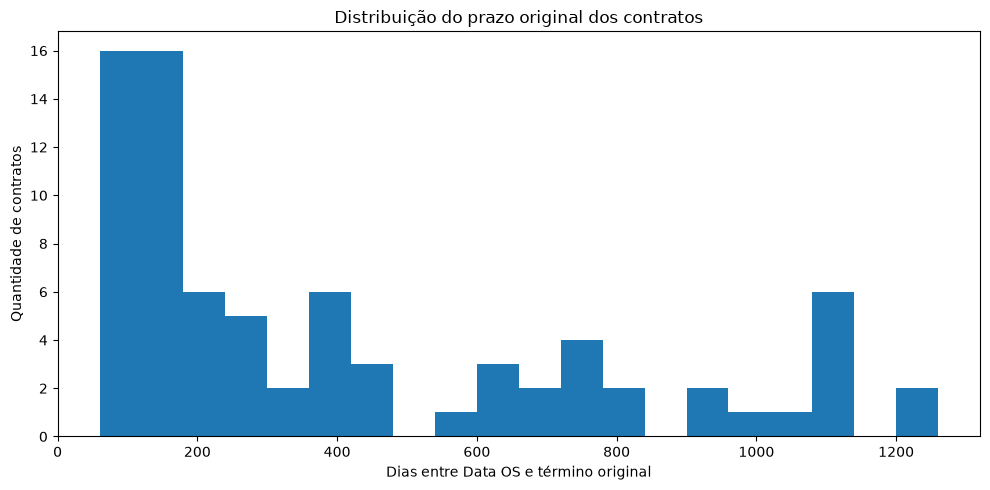

In [6]:
durations = analysis[
    "diferenca_termino_original_data_os_dias"
].dropna()

plt.figure(figsize=(10, 5))
plt.hist(durations, bins=20)
plt.title("Distribuição do prazo original dos contratos")
plt.xlabel("Dias entre Data OS e término original")
plt.ylabel("Quantidade de contratos")
plt.tight_layout()
plt.show()


## 6. Contratos por classificação e status

In [7]:
summary = (
    analysis.groupby(
        ["classificacao_contrato", "status_final_controle"],
        dropna=False,
    )
    .agg(
        quantidade_contratos=("id_contrato", "nunique"),
        prazo_medio_dias=("diferenca_termino_original_data_os_dias", "mean"),
        prazo_mediano_dias=("diferenca_termino_original_data_os_dias", "median"),
    )
    .reset_index()
    .sort_values("quantidade_contratos", ascending=False)
)
summary


,classificacao_contrato,status_final_controle,quantidade_contratos,prazo_medio_dias,prazo_mediano_dias
9,Reforma Parcial,CONCLUÍDO,38,165.79,120.00
1,Construção,EM ANDAMENTO,8,975.00,"1,080.00"
11,Reforma Parcial,RESCINDIDO,6,190.00,135.00
0,Construção,CONCLUÍDO,6,635.00,690.00
12,Reforma Parcial e Ampliação,CONCLUÍDO,4,232.50,210.00
10,Reforma Parcial,EM ANDAMENTO,3,360.00,360.00
6,Reforma Global e Ampliação,EM ANDAMENTO,2,690.00,690.00
4,Reforma Global,EM ANDAMENTO,2,630.00,630.00
3,Construção,SUSPENSO/PARALISADO,2,900.00,900.00
2,Construção,RESCINDIDO,2,"1,080.00","1,080.00"


## 7. Exportação da análise

In [8]:
output_path = REPORTS_DIR / "analise_rapida_prazos_originais.csv"
analysis.to_csv(output_path, index=False, encoding="utf-8-sig")

print("Arquivo gerado:", output_path)
print("Linhas:", len(analysis))


Arquivo gerado: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\reports\quick_analysis\analise_rapida_prazos_originais.csv
Linhas: 78
